In [3]:
import pandas as pd
import numpy as np
import pickle

word_embeddings = pickle.load(open('./data/word_embeddings_subset.p', 'rb'))
len(word_embeddings)

243

In [8]:
countryVector = word_embeddings['country']
print(type(countryVector))
print(countryVector)

<class 'numpy.ndarray'>
[-0.08007812  0.13378906  0.14355469  0.09472656 -0.04736328 -0.02355957
 -0.00854492 -0.18652344  0.04589844 -0.08154297 -0.03442383 -0.11621094
  0.21777344 -0.10351562 -0.06689453  0.15332031 -0.19335938  0.26367188
 -0.13671875 -0.05566406  0.07470703 -0.00070953  0.09375    -0.14453125
  0.04296875 -0.01916504 -0.22558594 -0.12695312 -0.0168457   0.05224609
  0.0625     -0.1484375  -0.01965332  0.17578125  0.10644531 -0.04760742
 -0.10253906 -0.28515625  0.10351562  0.20800781 -0.07617188 -0.04345703
  0.08642578  0.08740234  0.11767578  0.20996094 -0.07275391  0.1640625
 -0.01135254  0.0025177   0.05810547 -0.03222656  0.06884766  0.046875
  0.10107422  0.02148438 -0.16210938  0.07128906 -0.16210938  0.05981445
  0.05102539 -0.05566406  0.06787109 -0.03759766  0.04345703 -0.03173828
 -0.03417969 -0.01116943  0.06201172 -0.08007812 -0.14941406  0.11914062
  0.02575684  0.00302124  0.04711914 -0.17773438  0.04101562  0.05541992
  0.00598145  0.03027344 -0.07

In [9]:
def vec(w):
    return word_embeddings[w]

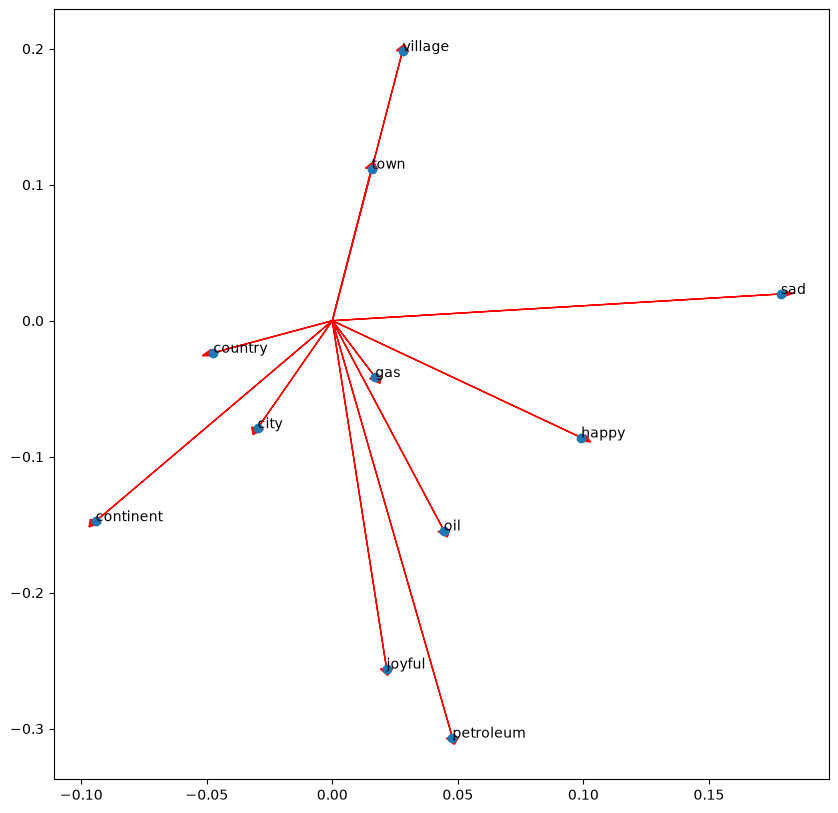

In [17]:
import matplotlib.pyplot as plt

words = ['oil', 'gas', 'happy', 'sad', 'city', 'town', 'village', 'country', 'continent', 'petroleum', 'joyful']

bag2d = np.array([vec(word) for word in words])
fig, ax = plt.subplots(figsize=(10, 10))

col1 = 4
col2 = 5

for word in bag2d:
    ax.arrow(0, 0, word[col1], word[col2], head_width=0.005, head_length=0.005, fc='r', ec='r', width=1e-5)

ax.scatter(bag2d[:, col1], bag2d[:, col2])

for i in range(len(words)):
    ax.annotate(words[i], (bag2d[i, col1], bag2d[i, col2]))

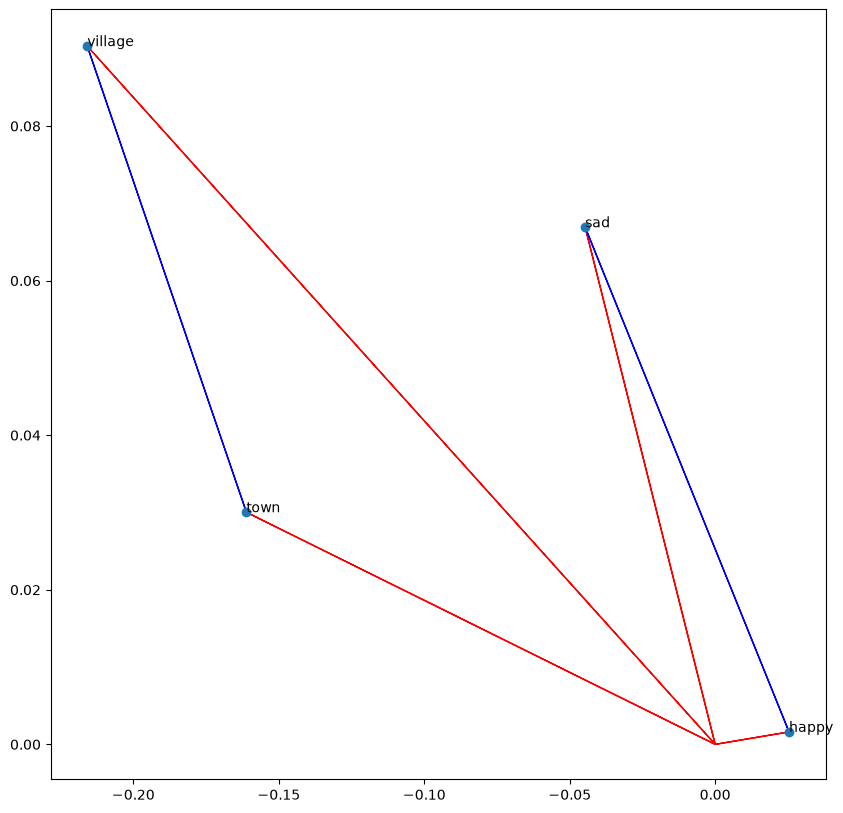

In [22]:
words = ['sad', 'happy', 'town', 'village']

bag2d = np.array([vec(word) for word in words])
fig, ax = plt.subplots(figsize=(10, 10))

col1 = 3
col2 = 2

for word in bag2d:
    ax.arrow(0, 0, word[col1], word[col2], head_width=0.0005, head_length=0.0005, fc='r', ec='r', width=1e-5)

village = vec('village')
town = vec('town')
diff = town - village
ax.arrow(village[col1], village[col2], diff[col1], diff[col2], fc='b', ec='b', width=1e-5)

sad = vec('sad')
happy = vec('happy')
diff = happy - sad
ax.arrow(sad[col1], sad[col2], diff[col1], diff[col2], fc='b', ec='b', width=1e-5)

ax.scatter(bag2d[:, col1], bag2d[:, col2])

for i in range(len(words)):
    ax.annotate(words[i], (bag2d[i, col1], bag2d[i, col2]))

In [23]:
print(np.linalg.norm(vec('town')))
print(np.linalg.norm(vec('sad')))

2.3858097
2.9004838


In [25]:
capital = vec('France') - vec('Paris')
country = vec('Madrid') + capital
print(country[0:5])

[-0.02905273 -0.2475586   0.53952026  0.20581055 -0.14862823]


In [26]:
diff = country - vec('Spain')
print(diff[0:10])

[-0.06054688 -0.06494141  0.37643433  0.08129883 -0.13007355 -0.00952148
 -0.03417969 -0.00708008  0.09790039 -0.01867676]


In [30]:
keys = word_embeddings.keys()
data = []
for key in keys:
    data.append(word_embeddings[key])

embedding = pd.DataFrame(data=data, index=keys)

def find_closest_word(v, k=1):
    diff = embedding.values - v
    delta = np.sum(diff * diff, axis=1)
    i = np.argmin(delta)
    return embedding.iloc[i].name

In [31]:
embedding.head()

,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,299
country,-0.080078,0.133789,0.143555,0.094727,-0.047363,-0.023560,-0.008545,-0.186523,0.045898,-0.081543,...,-0.145508,0.067383,-0.244141,-0.077148,0.047607,-0.075195,-0.149414,-0.044189,0.097168,0.067383
city,-0.010071,0.057373,0.183594,-0.040039,-0.029785,-0.079102,0.071777,0.013306,-0.143555,0.011292,...,0.024292,-0.168945,-0.062988,0.117188,-0.020508,0.030273,-0.247070,-0.122559,0.076172,-0.234375
China,-0.073242,0.135742,0.108887,0.083008,-0.127930,-0.227539,0.151367,-0.045654,-0.065430,0.034424,...,0.140625,0.087402,0.152344,0.079590,0.006348,-0.037842,-0.183594,0.137695,0.093750,-0.079590
Iraq,0.191406,0.125000,-0.065430,0.060059,-0.285156,-0.102539,0.117188,-0.351562,-0.095215,0.200195,...,-0.100586,-0.077148,-0.123047,0.193359,-0.153320,0.089355,-0.173828,-0.054688,0.302734,0.105957
oil,-0.139648,0.062256,-0.279297,0.063965,0.044434,-0.154297,-0.184570,-0.498047,0.047363,0.110840,...,-0.195312,-0.345703,0.217773,-0.091797,0.051025,0.061279,0.194336,0.204102,0.235352,-0.051025


In [32]:
find_closest_word(country)

'Spain'

In [33]:
find_closest_word(vec('Italy') - vec('Rome') + vec('Madrid'))

'Spain'

In [34]:
print(find_closest_word(vec('Berlin') + capital))

Germany
